# [3] Gridded EO Data

> Standardizing to H3 global grid indexing when working with rasters. For this example series, we focus on B04 (red), B03 (green), B02 (blue), and B08 (nir).

---
__Last Update:__ August 13, 2026

![Notebook 03 — Sentinel-2 scene → typed tile struct → H3 res-7 tessellation → per-cell timeseries](https://raw.githubusercontent.com/databrickslabs/geobrix/main/resources/images/diagrams/eo-series/eo-series-03.png)

This notebook uses the **RasterX** API ([Surfaces and levels](https://databrickslabs.github.io/geobrix/docs/api/execution-tiers), [RasterX Functions](https://databrickslabs.github.io/geobrix/docs/api/raster-functions)) to tessellate Sentinel-2 raster tiles to H3 resolution-7 grids and compute per-cell raster summaries. Key functions: `rst_summary` (tile metadata extraction) and `rst_merge_agg` (neighborhood aggregation across H3 k-rings).

The reader loads scenes as **[virtual tiles](https://databrickslabs.github.io/geobrix/docs/api/virtual-tiles)** by default — each row is a bytes-free `(path, window)` reference rather than the raster pixels, so a multi-gigabyte scene fans into many lightweight tiles without exhausting worker memory. Pixels are read lazily: a window materializes only when a pixel-producing `rst_*` op needs it.

## Imports + Config

In [0]:
import warnings
warnings.filterwarnings(
    "ignore",
    message=r".*make_tokens_by_line.*received a list of lines.*",
    category=UserWarning,
)

In [0]:
%run ./config_nb

... skipping spark.conf.set(spark.sql.adaptive.coalescePartitions.enabled) [Serverless?]: AnalysisException


geobrix 0.6.0: one wheel per runtime (+env5 / +env6); SQL functions register through databricks.labs.gbx.register(spark); the Python API is rasterx / gridx / vectorx. See https://databrickslabs.github.io/geobrix/docs/migration-0-6
geobrix: heavy (Catalyst) unavailable: Spark Connect session (Serverless); using light (48 functions)
geobrix: SQL unavailable: 5 functions (gbx_bng_cellarea, gbx_bng_eastnorthasbng, gbx_quadbin_distance, ...) need a SQL function wrapper, and SQL functions are unavailable here; using light


... catalog: 'geospatial_docs' (USE)
... schema: 'eo_series' (CREATE / USE)


... ETL_DIR: '/Volumes/geospatial_docs/eo_series/data'
... EO_DIR: '/Volumes/geospatial_docs/eo_series/data/alaska' (MKDIRS)


In [0]:
INTERACTIVE_PLOTS = False

In [0]:
# FORCE_REBUILD=True # to rebuild all this

## Data load

__Prepare initial band table for eventual tessellation.__

In [0]:
# set date as variable for consistency across bands.
# - you don't have to filter
filter_date = "2022-06-01"

__Filter `band_b02` (blue - 10m) to a single date (2021-06-01) from all available dates.__

In [0]:
b02_df = (
  spark.read.table("band_b02")
  .filter(col('date') == F.lit(filter_date))
)
print(f"count? {b02_df.count():,}")
b02_df.limit(15).display()

count? 14


item_id,band_name,date,out_file_path,out_file_sz,is_out_file_valid,last_update
S2A_MSIL2A_20220601T194911_R085_T08UPG_20220602T195342,B02,2022-06-01,/Volumes/geospatial_docs/eo_series/data/alaska/B02/B02_S2A_MSIL2A_20220601T194911_R085_T08UPG_20220602T195342.tif,63273397,true,2026-11-12T06:12:15.676Z
S2A_MSIL2A_20220601T194911_R085_T09UUV_20220602T173354,B02,2022-06-01,/Volumes/geospatial_docs/eo_series/data/alaska/B02/B02_S2A_MSIL2A_20220601T194911_R085_T09UUV_20220602T173354.tif,184515222,true,2026-11-12T06:12:15.676Z
S2A_MSIL2A_20220601T194911_R085_T09VUD_20220602T193134,B02,2022-06-01,/Volumes/geospatial_docs/eo_series/data/alaska/B02/B02_S2A_MSIL2A_20220601T194911_R085_T09VUD_20220602T193134.tif,104820996,true,2026-11-12T06:12:15.676Z
S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121,B02,2022-06-01,/Volumes/geospatial_docs/eo_series/data/alaska/B02/B02_S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121.tif,51887582,true,2026-11-12T06:12:15.676Z
S2A_MSIL2A_20220601T194911_R085_T08VPH_20220602T200243,B02,2022-06-01,/Volumes/geospatial_docs/eo_series/data/alaska/B02/B02_S2A_MSIL2A_20220601T194911_R085_T08VPH_20220602T200243.tif,21275175,true,2026-11-12T06:12:15.676Z
S2A_MSIL2A_20220601T194911_R085_T09UUB_20220602T200742,B02,2022-06-01,/Volumes/geospatial_docs/eo_series/data/alaska/B02/B02_S2A_MSIL2A_20220601T194911_R085_T09UUB_20220602T200742.tif,208778527,true,2026-11-12T06:12:15.676Z
S2A_MSIL2A_20220601T194911_R085_T09UVA_20220602T164456,B02,2022-06-01,/Volumes/geospatial_docs/eo_series/data/alaska/B02/B02_S2A_MSIL2A_20220601T194911_R085_T09UVA_20220602T164456.tif,39815188,true,2026-11-12T06:12:15.676Z
S2A_MSIL2A_20220601T194911_R085_T09UVV_20220602T181034,B02,2022-06-01,/Volumes/geospatial_docs/eo_series/data/alaska/B02/B02_S2A_MSIL2A_20220601T194911_R085_T09UVV_20220602T181034.tif,206685583,true,2026-11-12T06:12:15.676Z
S2A_MSIL2A_20220601T194911_R085_T09VVC_20220602T192814,B02,2022-06-01,/Volumes/geospatial_docs/eo_series/data/alaska/B02/B02_S2A_MSIL2A_20220601T194911_R085_T09VVC_20220602T192814.tif,234290019,true,2026-11-12T06:12:15.676Z
S2A_MSIL2A_20220601T194911_R085_T09UUA_20220602T195601,B02,2022-06-01,/Volumes/geospatial_docs/eo_series/data/alaska/B02/B02_S2A_MSIL2A_20220601T194911_R085_T09UUA_20220602T195601.tif,141619992,true,2026-11-12T06:12:15.676Z


For the purpose of raster data analysis GeoBrix provides functions for distributed GDAL data ingestion, focused on GTiff ('tif'). After loading the underlying files directly, we also add new columns from the following via function `finalize_tiled_band_tbl`:

* `rst_memsize` for 'size' 
* `rst_initnodata` to standardize the tile no data (avoids issues later in calcs)
* `rst_boundingbox` to generate tile bounding boxes
* `rst_srid` to pull out 'srid' from the raster metadata

__Notes:__

1. Since this involves a bit of computation, we persist out as Delta Table to then use multiple times below.
1. Operation can take a few minutes using the configuration described at top of notebook (more if doing all of Alaska).
1. We also OPTIMIZE (table layout) based on item_id which will help future ops.

> **Serverless note:** the `gtiff` reader is scoped **per band** (`tifs_for(band)`); `tileSize` plans a 2048×2048 pixel grid per scene, so a 5490×5490 COG fans into ~9 virtual windows. Each window is a bytes-free path+window reference by default — pixels are read lazily when a pixel-producing `rst_*` op needs them. `finalize_tiled_band_tbl` repartitions to one tile per task (Serverless can’t raise shuffle partitions).

__Read the downloaded tifs.__

> This is a reader for all the tifs, but we inner join on various bands of interest to put them into separate tables.

In [0]:
ls -lh $EO_DIR

total 32K
drwxrwxrwx 2 nobody nogroup 4.0K Nov 12 06:11 B02/
drwxrwxrwx 2 nobody nogroup 4.0K Nov 12 06:11 B03/
drwxrwxrwx 2 nobody nogroup 4.0K Nov 12 06:11 B04/
drwxrwxrwx 2 nobody nogroup 4.0K Nov 12 06:11 B08/
drwxrwxrwx 2 nobody nogroup 4.0K Nov 12 06:11 cell_assets_20261112-060424.delta/
drwxrwxrwx 2 nobody nogroup 4.0K Nov 12 06:11 _gbxrepair_B02/
drwxrwxrwx 2 nobody nogroup 4.0K Nov 12 06:11 _gbxverify_B02/
drwxrwxrwx 2 nobody nogroup 4.0K Nov 12 06:11 out/


In [0]:
def tifs_for(band):
  # Per-band read: load ONLY this band’s subdir. Under the 0.5.0 virtual-tile
  # default the reader returns bytes-free path+window references; tileSize plans
  # a 2048x2048 pixel grid per scene (~9 windows for a 5490x5490 COG). Pixels are
  # read lazily: each window materializes only when a pixel-producing rst_* op needs it.
  return (
    spark
      .read
      .format("gtiff_gbx")
        .option("tileSize", "2048,2048")
        .option("filterRegex", r".*[.]tif$")
      .load(f"{EO_DIR}/{band}")
    .withColumn("out_file_path", F.replace("source", F.lit("dbfs:/"), F.lit("/")))
    .drop("source")
  )

In [0]:
b02_df = b02_df.join(tifs_for("B02"), on=['out_file_path'])

In [0]:
b02_df.limit(3).display()

out_file_path,item_id,band_name,date,out_file_sz,is_out_file_valid,last_update,tile
/Volumes/geospatial_docs/eo_series/data/alaska/B02/B02_S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121.tif,S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121,B02,2022-06-01,51887582,true,2026-11-12T06:12:15.676Z,"[-1, null, ""/Volumes/geospatial_docs/eo_series/data/alaska/B02/B02_S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121.tif"", null, [0, 0, 2048, 2048], null, null, null, {""format"": ""gtiff"", ""count"": ""1"", ""height"": ""10980"", ""driver"": ""GTiff"", ""sourcePath"": ""/Volumes/geospatial_docs/eo_series/data/alaska/B02/B02_S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121.tif"", ""path_file_size"": ""51887582"", ""width"": ""10980""}]"
/Volumes/geospatial_docs/eo_series/data/alaska/B02/B02_S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121.tif,S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121,B02,2022-06-01,51887582,true,2026-11-12T06:12:15.676Z,"[-1, null, ""/Volumes/geospatial_docs/eo_series/data/alaska/B02/B02_S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121.tif"", null, [2048, 0, 2048, 2048], null, null, null, {""format"": ""gtiff"", ""count"": ""1"", ""height"": ""10980"", ""driver"": ""GTiff"", ""sourcePath"": ""/Volumes/geospatial_docs/eo_series/data/alaska/B02/B02_S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121.tif"", ""path_file_size"": ""51887582"", ""width"": ""10980""}]"
/Volumes/geospatial_docs/eo_series/data/alaska/B02/B02_S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121.tif,S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121,B02,2022-06-01,51887582,true,2026-11-12T06:12:15.676Z,"[-1, null, ""/Volumes/geospatial_docs/eo_series/data/alaska/B02/B02_S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121.tif"", null, [4096, 0, 2048, 2048], null, null, null, {""format"": ""gtiff"", ""count"": ""1"", ""height"": ""10980"", ""driver"": ""GTiff"", ""sourcePath"": ""/Volumes/geospatial_docs/eo_series/data/alaska/B02/B02_S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121.tif"", ""path_file_size"": ""51887582"", ""width"": ""10980""}]"


> **Light tiles in the output above.** Because the reader is virtual by default, this first row shows a **bytes-free** tile: `tile.raster` is `null`, while `tile.path` and `tile.window` carry the `(path, window)` reference. That is a [virtual tile](https://databrickslabs.github.io/geobrix/docs/api/virtual-tiles) — no pixels have been read yet. The pixels materialize downstream, one window at a time, only where a pixel-producing `rst_*` op needs them (e.g. `rst_initnodata` inside `finalize_tiled_band_tbl`).

In [0]:
df_tile = finalize_tiled_band_tbl(b02_df, "band_b02_tile", 
                                  do_overwrite=FORCE_REBUILD, do_display=False) # <- don't overwrite (unless you want to)
print(f"count? {df_tile.count():,}")
df_tile.limit(1).show(vertical=True) # <- show + limiting for ipynb only

... number of files to process? 504
count? 504
-RECORD 0-------------------------
 item_id   | S2A_MSIL2A_202206... 
 band_name | B02                  
 date      | 2022-06-01           
 tile      | {-1, NULL, /Volum... 
 size      | 8388608              
 bbox      | [01 03 00 00 00 0... 
 srid      | 32608                



In [0]:
# sql(f"DESCRIBE HISTORY band_b02_tile").display()

In [0]:
(
  df_tile
    .select(DBF.st_astext(DBF.st_geomfromwkb("bbox","srid")).alias("bbox_wkt"), "srid")
    .groupBy("bbox_wkt", "srid")
      .count()
  .limit(3)
  .display()
)

bbox_wkt,srid,count
"POLYGON((620480 6.17956e+06,620480 6.20004e+06,600000 6.20004e+06,600000 6.17956e+06,620480 6.17956e+06))",32608,1
"POLYGON((640960 6.17956e+06,640960 6.20004e+06,620480 6.20004e+06,620480 6.17956e+06,640960 6.17956e+06))",32608,1
"POLYGON((661440 6.17956e+06,661440 6.20004e+06,640960 6.20004e+06,640960 6.17956e+06,661440 6.17956e+06))",32608,1


## Initial Tile Plots

> These are samples from the full data.

_[1] Tile raster plot._

In [0]:
# The tile table is virtual (bytes-free path+window refs); plot_raster needs
# pixels, so materialize the sampled rows for display (applies the pending
# nodata instruction and bakes bytes). This is the explicit opt-out from the
# lazy default -- see https://databrickslabs.github.io/geobrix/docs/api/virtual-tiles
# Drop empty/edge tiles first: an all-NoData H3 cell renders as a blank grey
# box (NoData is masked transparent over the axes facecolor), not a raster.
to_plot = (
  df_tile
    .limit(10)
    .repartition(10, "tile")
    .withColumn("tile", rx.rst_initnodata("tile", materialize=True))
    .filter(rx.rst_isempty("tile") == False)
    .collect()
)

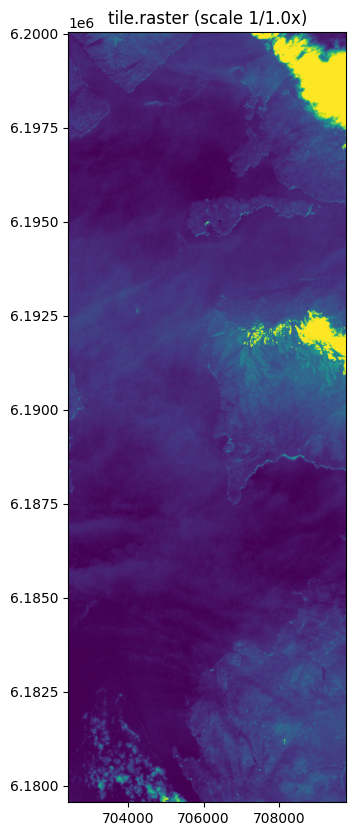

<Axes: title={'center': 'tile.raster (scale 1/1.0x)'}>

In [0]:
# Single-band tile -> viridis. Index 0 is now a covered tile (empties filtered above).
plot_raster(to_plot[0]["tile"]["raster"])

_[2] Bounding box plot._

> Just for a subset of 'item_ids'. __Note: we specify the SRID for rendering__ since it is not 4326. We got this information earlier.

In [0]:
to_plot = (
  df_tile
    .filter(col("item_id").contains(F.lit("_R085_")))
    .select(DBF.st_astext(DBF.st_geomfromwkb("bbox", "srid")).alias("bbox_wkt"), "srid")
    .groupBy("bbox_wkt", "srid")
      .count()
    .orderBy(F.desc("count"))
)
print(f"count? {to_plot.count():,}")
to_plot.limit(3).display()

count? 432


bbox_wkt,srid,count
"POLYGON((320480 6.07954e+06,320480 6.10002e+06,300000 6.10002e+06,300000 6.07954e+06,320480 6.07954e+06))",32609,2
"POLYGON((340960 6.07954e+06,340960 6.10002e+06,320480 6.10002e+06,320480 6.07954e+06,340960 6.07954e+06))",32609,2
"POLYGON((361440 6.07954e+06,361440 6.10002e+06,340960 6.10002e+06,340960 6.07954e+06,361440 6.07954e+06))",32609,2


_Couple of different SRIDs._

In [0]:
to_plot.groupBy("srid").count().orderBy("srid").display()

srid,count
32608,108
32609,324


In [0]:
to_plot_32608 = to_plot.filter("srid = 32609")


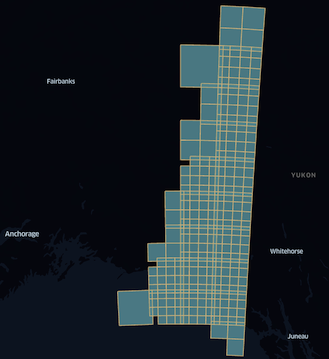

In [0]:
displayHTML("""<img src="..." width="25%">""")

_Uncomment the following within databricks for actual results._

In [0]:
# to_plot_4326 = (
#   to_plot_32608
#     .withColumn(
#       "wkt",
#       DBF.st_astext(
#         DBF.st_transform(DBF.st_geomfromwkt("bbox_wkt", "srid"), 4326))
#       ).alias("wkt")
# )

# gdf_32608 = as_gdf(to_plot_4326)
# gdf_32608.explore()

## TIF Summary Information

`rst_summary` returns a JSON string with per-tile metadata including dimensions, coordinate system, band info, and nodata values. See [RasterX Functions](https://databrickslabs.github.io/geobrix/docs/api/raster-functions).

In [0]:
summary_df = (
  df_tile
    .withColumn("summary_tile", rx.rst_summary("tile"))
    .selectExpr("summary_tile", "* except(summary_tile)")
)
summary_df.limit(1).show(vertical=True) # <-- show + limiting for ipynb only

-RECORD 0----------------------------
 summary_tile | {\n  "description... 
 item_id      | S2A_MSIL2A_202206... 
 band_name    | B02                  
 date         | 2022-06-01           
 tile         | {-1, NULL, /Volum... 
 size         | 8388608              
 bbox         | [01 03 00 00 00 0... 
 srid         | 32608                



> [2b] Example parsing out band information from summary, in this example we count 'band.noDataValue' (which we previously standardized). __Note: there are other helper functions as well for metadata not shown, e.g. `rst_bandmetadata`.__ We haven't yet stacked bands (will do in notebook 04), so dealing with single band TIFFs up to now.

In [0]:
# we use an exemplar to further parse structured metadata from the summary, in this case for bands. 
# - then we group by the numeric value for `band.noDataValue` and see if all is consistent
# - it is because we previously standardized it
example_band_obj = """[{"band":1,"block":[512,512],"type":"UInt16","colorInterpretation":"Gray","noDataValue":0.0,"overviews":[{"size":[5490,5490]},{"size":[2745,2745]},{"size":[1373,1373]},{"size":[687,687]},{"size":[344,344]}],"metadata":{}}]"""

(
    summary_df   
        .selectExpr("summary_tile:['bands'] as band_obj")
        .select(F.from_json("band_obj", F.schema_of_json(example_band_obj)).alias("bands"))
        .select(F.explode("bands").alias("band"))    
        .groupBy("band.noDataValue")
            .count()
).display()

noDataValue,count
0.0,504


## Tessellate @ H3 resolution=7

> To avoid re-computation per run, persisting the initial h3 tessellation as delta table. __Note: H3 Resolution 7 has an average area of 5km^2.__ This produces -700K tessellated tiles for Alaska (if doing everything, we are just focused on a single county). This will take some time to run (depending on cluster config, e.g. ~10 minutes for the one provided).

> **Serverless note:** `rst_h3_tessellate` is a **table function** (SQL `LATERAL`); `gen_tessellate_tiled_band` invokes it via `LATERAL`, rebuilds the `tile` struct, and repartitions to one tile per task for parallelism.

In [0]:
h3_resolution = 7
df_tile = spark.table("band_b02_tile")

In [0]:
df_tile.limit(1).show(vertical=True) # <- show + limiting for ipynb only

-RECORD 0-------------------------
 item_id   | S2A_MSIL2A_202206... 
 band_name | B02                  
 date      | 2022-06-01           
 tile      | {-1, NULL, /Volum... 
 size      | 8388608              
 bbox      | [01 03 00 00 00 0... 
 srid      | 32608                



__Function to perform H3 tessellation for any/all bands.__

In [0]:
# %sql
# drop table if exists band_b02_h3

In [0]:
df_h3_b02 = gen_tessellate_tiled_band(
  df_tile,
  h3_resolution,
  "band_b02_h3", 
  do_overwrite=FORCE_REBUILD,
  do_display=False
)

print(f"count? {df_h3_b02.count():,}")
df_h3_b02.limit(1).show(vertical=True) # <- show + limiting for ipynb only

count? 50,565
-RECORD 0-------------------------
 cellid    | 608312895943475199   
 tile      | {6083128959434751... 
 item_id   | S2A_MSIL2A_202206... 
 band_name | B02                  
 date      | 2022-06-01           
 size      | 8388608              
 bbox      | [01 03 00 00 00 0... 
 srid      | 32609                



_We see there are a higher number of individual H3 cells given that some tiles have cellids in common._

In [0]:
print(f"""count? { df_h3_b02.groupBy("cellid").count().count():,}""") 
display (
  df_h3_b02
  .groupBy("cellid")
    .count()
  .orderBy(F.desc("count"))
  .limit(5)
)

count? 28,950


cellid,count
608314921809084415,15
608314954457546751,12
608314920081031167,12
608314791366230015,12
608314804905443327,12


In [0]:
df_plot_h3_b02 = (
  df_h3_b02
  .filter(col("item_id").contains("_R085_"))
  .groupBy("cellid")
    .count()
)
print(f"count? {df_plot_h3_b02.count():,}")   

count? 28,950


_Let's look at the ~50K cellids (with overlap counts) for 'item_ids' that contain `_R085_` (overlapping the bounding box earlier). Sidenote: since Alaska has some land on each side of the antimeridian, pull your mouse east to see the bulk of the results when rendering close to the boundary (not relevant for this output)._


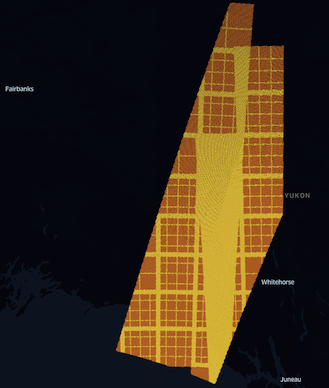

In [0]:
displayHTML("""<img src="..." width="25%">""")

_Uncomment the following within databricks for actual results._

In [0]:
# gdf_h3_b02 = cells_as_gdf(df_plot_h3_b02.limit(10_000), extra_cols=['count']) # <- limiting results for notebook
# gdf_h3_b02.explore(column='count', cmap='autumn_r')

### Repeat for the other bands of interest

> Note: we are not doing an overwrite here, so if the table exists, it will just be returned.

__Band 03 (Green) tile and h3 tables.__

In [0]:
b03_df = (
  spark.read.table("band_b03")
  .filter(col('date') == F.lit(filter_date))
  .join(tifs_for("B03"), on=['out_file_path'])
)

b03_df.limit(1).display()

out_file_path,item_id,band_name,date,out_file_sz,is_out_file_valid,last_update,tile
/Volumes/geospatial_docs/eo_series/data/alaska/B03/B03_S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121.tif,S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121,B03,2022-06-01,51407991,true,2026-11-12T06:12:29.322Z,"[-1, null, ""/Volumes/geospatial_docs/eo_series/data/alaska/B03/B03_S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121.tif"", null, [0, 0, 2048, 2048], null, null, null, {""format"": ""gtiff"", ""count"": ""1"", ""height"": ""10980"", ""driver"": ""GTiff"", ""sourcePath"": ""/Volumes/geospatial_docs/eo_series/data/alaska/B03/B03_S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121.tif"", ""path_file_size"": ""51407991"", ""width"": ""10980""}]"


In [0]:
finalize_tiled_band_tbl(
  b03_df, 
  "band_b03_tile", 
  do_overwrite=FORCE_REBUILD, # <- don't overwrite (unless you want to)
  do_display=False
)

... number of files to process? 504


DataFrame[item_id: string, band_name: string, date: date, tile: struct<cellid:bigint,raster:binary,path:string,path_mode:string,window:struct<col_off:int,row_off:int,width:int,height:int>,clip_polygon:binary,clip_crs:string,crs:string,metadata:map<string,string>>, size: bigint, bbox: binary, srid: int]

In [0]:
gen_tessellate_tiled_band(
  spark.table("band_b03_tile"),
  h3_resolution, 
  "band_b03_h3", 
  do_overwrite=FORCE_REBUILD, # <- don't overwrite (unless you want to)
  do_display=False
) 

DataFrame[cellid: bigint, tile: struct<cellid:bigint,raster:binary,path:string,path_mode:string,window:struct<col_off:int,row_off:int,width:int,height:int>,clip_polygon:binary,clip_crs:string,crs:string,metadata:map<string,string>>, item_id: string, band_name: string, date: date, size: bigint, bbox: binary, srid: int]

__Band 04 (Red) tile and h3 tables.__

In [0]:
b04_df = (
  spark.read.table("band_b04")
  .filter(col('date') == F.lit(filter_date))
  .join(tifs_for("B04"), on=['out_file_path'])
)

b04_df.limit(1).display()

out_file_path,item_id,band_name,date,out_file_sz,is_out_file_valid,last_update,tile
/Volumes/geospatial_docs/eo_series/data/alaska/B04/B04_S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121.tif,S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121,B04,2022-06-01,50857031,true,2026-11-12T06:12:39.185Z,"[-1, null, ""/Volumes/geospatial_docs/eo_series/data/alaska/B04/B04_S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121.tif"", null, [0, 0, 2048, 2048], null, null, null, {""format"": ""gtiff"", ""count"": ""1"", ""height"": ""10980"", ""driver"": ""GTiff"", ""sourcePath"": ""/Volumes/geospatial_docs/eo_series/data/alaska/B04/B04_S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121.tif"", ""path_file_size"": ""50857031"", ""width"": ""10980""}]"


In [0]:
finalize_tiled_band_tbl(
  b04_df,
  "band_b04_tile",
  do_overwrite=FORCE_REBUILD, # <- don't overwrite (unless you want to)
  do_display=False
) 

... number of files to process? 504


DataFrame[item_id: string, band_name: string, date: date, tile: struct<cellid:bigint,raster:binary,path:string,path_mode:string,window:struct<col_off:int,row_off:int,width:int,height:int>,clip_polygon:binary,clip_crs:string,crs:string,metadata:map<string,string>>, size: bigint, bbox: binary, srid: int]

In [0]:
gen_tessellate_tiled_band(
  spark.table("band_b04_tile"),
  h3_resolution, "band_b04_h3",
  do_overwrite=FORCE_REBUILD, # <- don't overwrite (unless you want to)
  do_display=False
) 

DataFrame[cellid: bigint, tile: struct<cellid:bigint,raster:binary,path:string,path_mode:string,window:struct<col_off:int,row_off:int,width:int,height:int>,clip_polygon:binary,clip_crs:string,crs:string,metadata:map<string,string>>, item_id: string, band_name: string, date: date, size: bigint, bbox: binary, srid: int]

__Band 08 (NIR) tile and h3 tables.__

In [0]:
b08_df = (
  spark.read.table("band_b08")
  .filter(col('date') == F.lit(filter_date))
  .join(tifs_for("B08"), on=['out_file_path'])
)

b08_df.limit(1).display()

out_file_path,item_id,band_name,date,out_file_sz,is_out_file_valid,last_update,tile
/Volumes/geospatial_docs/eo_series/data/alaska/B08/B08_S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121.tif,S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121,B08,2022-06-01,50680637,true,2026-11-12T06:12:49.708Z,"[-1, null, ""/Volumes/geospatial_docs/eo_series/data/alaska/B08/B08_S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121.tif"", null, [0, 0, 2048, 2048], null, null, null, {""format"": ""gtiff"", ""count"": ""1"", ""height"": ""10980"", ""driver"": ""GTiff"", ""sourcePath"": ""/Volumes/geospatial_docs/eo_series/data/alaska/B08/B08_S2A_MSIL2A_20220601T194911_R085_T08UPF_20220602T201121.tif"", ""path_file_size"": ""50680637"", ""width"": ""10980""}]"


In [0]:
finalize_tiled_band_tbl(b08_df, "band_b08_tile", do_overwrite=FORCE_REBUILD, do_display=False) # <- don't overwrite (unless you want to)

... number of files to process? 504


DataFrame[item_id: string, band_name: string, date: date, tile: struct<cellid:bigint,raster:binary,path:string,path_mode:string,window:struct<col_off:int,row_off:int,width:int,height:int>,clip_polygon:binary,clip_crs:string,crs:string,metadata:map<string,string>>, size: bigint, bbox: binary, srid: int]

In [0]:
gen_tessellate_tiled_band(spark.table("band_b08_tile"), h3_resolution, "band_b08_h3", do_overwrite=FORCE_REBUILD, do_display=False) # <- don't overwrite (unless you want to)

DataFrame[cellid: bigint, tile: struct<cellid:bigint,raster:binary,path:string,path_mode:string,window:struct<col_off:int,row_off:int,width:int,height:int>,clip_polygon:binary,clip_crs:string,crs:string,metadata:map<string,string>>, item_id: string, band_name: string, date: date, size: bigint, bbox: binary, srid: int]

## K-Rings

> Once your rasters have been gridded, you can take advantage of calls such as K-Rings.

_We are just doing a kring around a H3 resolution 5 area in this example. Since our data is @ resolution 7, we can use the `h3_toparent` function available in product._

In [0]:
h3_df = spark.table("band_b02_h3")

In [0]:
kring_cellid = (
  h3_df
    .groupBy("cellid")
      .count()
    .orderBy(F.desc("count"))
    .selectExpr("h3_toparent(cellid, 5)")
).first()[0]

kring_cellid

599307723460313087

_Also, we are choosing to go out 3 rings from our center cell of interest in this example, using built-in product [h3_kring](https://docs.databricks.com/en/sql/language-manual/functions/h3_kring.html) for just the h3 cells around the provide one(s)._

`rst_merge_agg` merges all tiles whose H3 cell falls within the k-ring neighborhood into a single raster — useful for building spatial context around a cell of interest. Note: `h3_kring` and `h3_toparent` are Databricks built-in H3 functions, not GeoBrix.

In [0]:
from databricks.labs.gbx.rasterx import functions as rx

kring_df = (
  h3_df
    .filter(DBF.h3_toparent("cellid", 5) == kring_cellid)
    .withColumn("kring", F.expr("explode(h3_kring(cellid, 3))"))
    .groupBy("kring", "date")
      .agg(rx.rst_merge_agg("tile").alias("content"))  # the mosaic's GeoTIFF bytes
    .withColumn("tile", rx.rst_fromcontent("content", F.lit("GTiff")))
    .drop("content")
)
print(f"count? {kring_df.count():,}")
kring_df.limit(1).show(vertical=True) # <- show + limiting for ipynb only

count? 157
-RECORD 0---------------------
 kring | 608311841394786303   
 date  | 2022-06-01           
 tile  | {0, [49 49 2A 00 ... 



_Here is a plot of k-rings around our selected center cellid._

> Hint: zoom out to see all.

In [0]:
to_plot = (
  kring_df
  .select("kring")
)


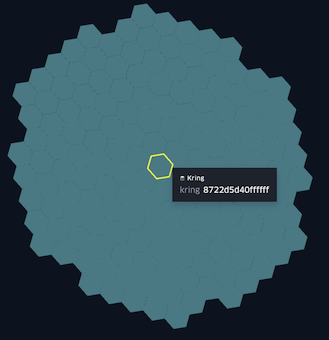

In [0]:
displayHTML("""<img src="..." width="25%">""")

_Uncomment the following within databricks for actual results._

In [0]:
# cells_as_gdf(to_plot, cell_col = "kring").explore()

_Here is one of the rasters included in the kring data._

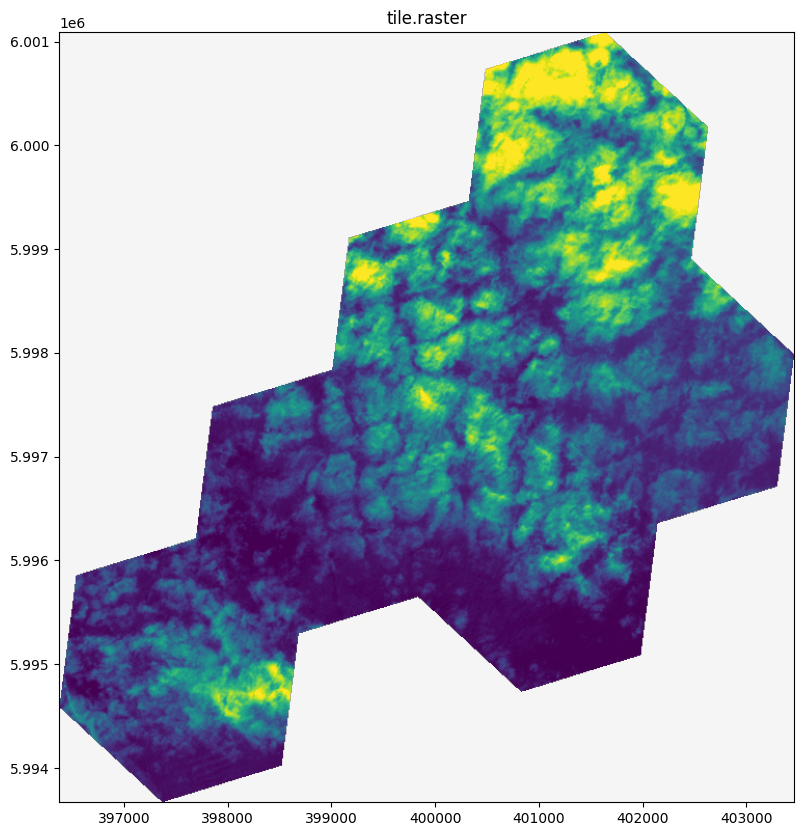

<Axes: title={'center': 'tile.raster'}>

In [0]:
plot_raster(kring_df.select("tile.raster").first()[0])

Multi-layer view: the merged raster overlaid with its H3 k-ring grid — pan and zoom to explore the tessellation.

In [0]:
if INTERACTIVE_PLOTS:
    from databricks.labs.gbx.vizx import raster_layer, grid_layer, plot_interactive
    plot_interactive([
        raster_layer(kring_df.select("tile.raster").first()[0]),
        grid_layer(kring_df, grid_system="h3", cellid_col="kring", opacity=0.25),
    ])

## Raster to Timeseries projection

> __With the power of expression that rasterio provides + the power of distribution that GeoBrix provides__, we can easily convert rasters to numerical values with arbitrary mathematical complexity. Since all of our imagery is timestamped, our raster to number projection in effect is creating time series bound to H3 cells.

In [0]:
def rio_mean_band(dataset):
  try:
    return dataset.statistics(bidx = 1).mean
  except:
    return 0.0

measure_df = kring_df.withColumn(
  "rio_mean", rst_apply("tile", lambda dataset: rio_mean_band(dataset) )
)

In [0]:
daily_measure_df = (
  measure_df
    .selectExpr(
      "kring as cellid",
      "date",
      "rio_mean",
      "tile.raster"
    )
    .where("rio_mean > 0")
    .groupBy("cellid", "date")
    .agg(
      F.avg("rio_mean").alias("measure"),
      F.first("raster").alias("raster")
    )
)
daily_measure_df.limit(1).show(vertical=True) # <- show + limiting for ipynb only

-RECORD 0-----------------------
 cellid  | 608311841394786303   
 date    | 2022-06-01           
 measure | 1987.4602503690023   
 raster  | [49 49 2A 00 08 0... 



_At this point our data effectively became timeseries data and can be modeled as virtual IOT  devices that are fixed in spatial context. We can easily visualise data for individual dates in a spatial contex by leveraging our H3 locations._

In [0]:
df_filter_date = daily_measure_df.where(f"date == '{filter_date}'")


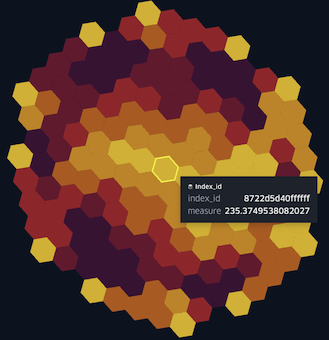

In [0]:
displayHTML("""<img src="..." width="25%">""")

_Uncomment the following within databricks for actual results._

In [0]:
# cells_as_gdf(df_filter_date, extra_cols=['measure']).explore(column='measure', cmap='autumn_r')